11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total Pola: 50000 | Latih: (40000, 784) | Validasi: (5000, 784) | Uji: (5000, 784)


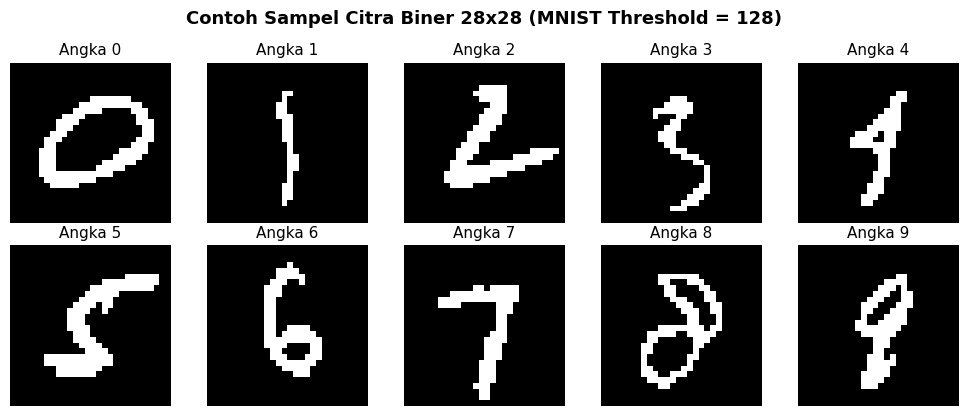

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.datasets import mnist
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

(x_m_tr, y_m_tr), (x_m_te, y_m_te) = mnist.load_data()
x_mnist_all = np.concatenate([x_m_tr, x_m_te], axis=0)
y_mnist_all = np.concatenate([y_m_tr, y_m_te], axis=0)

def siapkan_dataset_biner(samples_per_class=5000, threshold=128, seed=42):
    rng = np.random.default_rng(seed)
    idx_all = np.concatenate([
        rng.choice(np.where(y_mnist_all == a)[0], size=samples_per_class, replace=False)
        for a in range(10)
    ])
    X_bin_img = (x_mnist_all[idx_all] >= threshold).astype(np.float32)
    y_all = y_mnist_all[idx_all]
    X_flat = X_bin_img.reshape(-1, 784)

    X_train, X_temp, y_train, y_temp = train_test_split(
        X_flat, y_all, test_size=0.20, stratify=y_all, random_state=seed
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=seed
    )
    return X_train, X_val, X_test, y_train, y_val, y_test, X_bin_img, y_all

X_tr_50k, X_va_50k, X_te_50k, y_tr_50k, y_va_50k, y_te_50k, img_50k, lbl_50k = siapkan_dataset_biner(
    samples_per_class=5000, threshold=128, seed=42
)

print(f"Total Pola: {len(img_50k)} | Latih: {X_tr_50k.shape} | Validasi: {X_va_50k.shape} | Uji: {X_te_50k.shape}")

fig, axes = plt.subplots(2, 5, figsize=(10, 4.2))
for angka, ax in enumerate(axes.flat):
    ax.imshow(img_50k[np.where(lbl_50k == angka)[0][0]], cmap='gray')
    ax.set_title(f"Angka {angka}", fontsize=11)
    ax.axis('off')
plt.suptitle("Contoh Sampel Citra Biner 28x28 (MNIST Threshold = 128)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("gambar_1_sampel_biner.png", dpi=300, bbox_inches='tight')
plt.show()

In [2]:
class BackpropNguyenWidrowMomentum:
    def __init__(self, n_input=784, n_h1=16, n_h2=16, n_output=10, seed=42):
        self.rng = np.random.default_rng(seed)
        self.V1, self.b1 = self._nguyen_widrow(n_input, n_h1)
        self.V2, self.b2 = self._nguyen_widrow(n_h1, n_h2)
        self.W3 = self.rng.uniform(-0.5, 0.5, (n_h2, n_output)).astype(np.float32)
        self.b3 = self.rng.uniform(-0.5, 0.5, (1, n_output)).astype(np.float32)
        self._reset_momentum()

    def _nguyen_widrow(self, n_in, n_out):
        beta = float(0.7 * (n_out ** (1.0 / n_in)))
        W = self.rng.uniform(-0.5, 0.5, (n_in, n_out)).astype(np.float32)
        W_nw = (np.float32(beta) * W) / (np.linalg.norm(W, axis=0, keepdims=True) + np.float32(1e-12))
        b_nw = self.rng.uniform(-beta, beta, (1, n_out)).astype(np.float32)
        return W_nw, b_nw

    def _reset_momentum(self):
        self.prev_dV1 = np.zeros_like(self.V1); self.prev_db1 = np.zeros_like(self.b1)
        self.prev_dV2 = np.zeros_like(self.V2); self.prev_db2 = np.zeros_like(self.b2)
        self.prev_dW3 = np.zeros_like(self.W3); self.prev_db3 = np.zeros_like(self.b3)

    @staticmethod
    def _sigmoid(x):
        return 1.0 / (1.0 + np.exp(-np.clip(x, -50.0, 50.0)))

    def forward(self, X):
        X32 = X.astype(np.float32, copy=False)
        Z1 = self._sigmoid(X32 @ self.V1 + self.b1)
        Z2 = self._sigmoid(Z1 @ self.V2 + self.b2)
        Y  = self._sigmoid(Z2 @ self.W3 + self.b3)
        return Z1, Z2, Y

    def predict(self, X):
        return np.argmax(self.forward(X)[2], axis=1)

    def evaluate(self, X, y):
        T = np.eye(10, dtype=np.float32)[y]
        Y = self.forward(X)[2]
        return float(np.mean((T - Y) ** 2)), float(np.mean(np.argmax(Y, axis=1) == y) * 100.0)

    def fit(self, X_train, y_train, X_val, y_val, alpha=0.2, mu=0.9,
            max_epoch=120, target_mse=0.005, batch_size=64,
            early_stopping=True, patience=20):
        X_train = X_train.astype(np.float32, copy=False)
        X_val   = X_val.astype(np.float32, copy=False)
        T_train = np.eye(10, dtype=np.float32)[y_train]
        n = X_train.shape[0]
        self._reset_momentum()

        history = {'epoch': [], 'train_mse': [], 'val_mse': [], 'train_acc': [], 'val_acc': [],
                   'stopped_reason': '', 'best_epoch': 1}
        best_val_mse, best_weights, best_epoch, no_improve = float('inf'), None, 1, 0
        mu32 = np.float32(mu)

        for epoch in range(1, max_epoch + 1):
            perm = self.rng.permutation(n)
            X_shuf, T_shuf = X_train[perm], T_train[perm]
            for start in range(0, n, batch_size):
                Xb, Tb = X_shuf[start:start + batch_size], T_shuf[start:start + batch_size]
                inv_m = np.float32(alpha / Xb.shape[0])

                Z1, Z2, Y = self.forward(Xb)
                d3 = (Tb - Y) * Y * (1.0 - Y)
                d2 = (d3 @ self.W3.T) * Z2 * (1.0 - Z2)
                d1 = (d2 @ self.V2.T) * Z1 * (1.0 - Z1)

                dW3 = (Z2.T @ d3) * inv_m + mu32 * self.prev_dW3
                db3 = np.sum(d3, axis=0, keepdims=True) * inv_m + mu32 * self.prev_db3
                dV2 = (Z1.T @ d2) * inv_m + mu32 * self.prev_dV2
                db2 = np.sum(d2, axis=0, keepdims=True) * inv_m + mu32 * self.prev_db2
                dV1 = (Xb.T @ d1) * inv_m + mu32 * self.prev_dV1
                db1 = np.sum(d1, axis=0, keepdims=True) * inv_m + mu32 * self.prev_db1

                self.W3 += dW3; self.b3 += db3
                self.V2 += dV2; self.b2 += db2
                self.V1 += dV1; self.b1 += db1
                self.prev_dW3, self.prev_db3 = dW3, db3
                self.prev_dV2, self.prev_db2 = dV2, db2
                self.prev_dV1, self.prev_db1 = dV1, db1

            tr_mse, tr_acc = self.evaluate(X_train, y_train)
            va_mse, va_acc = self.evaluate(X_val, y_val)
            history['epoch'].append(epoch)
            history['train_mse'].append(tr_mse); history['val_mse'].append(va_mse)
            history['train_acc'].append(tr_acc); history['val_acc'].append(va_acc)

            if va_mse < best_val_mse - 1e-5:
                best_val_mse, best_epoch, no_improve = va_mse, epoch, 0
                best_weights = [w.copy() for w in (self.V1, self.b1, self.V2, self.b2, self.W3, self.b3)]
            else:
                no_improve += 1

            if tr_mse <= target_mse:
                if early_stopping and best_weights is not None:
                    self.V1, self.b1, self.V2, self.b2, self.W3, self.b3 = best_weights
                    history['stopped_reason'] = f'Target MSE tercapai (pakai bobot terbaik epoch {best_epoch})'
                else:
                    best_epoch = epoch
                    history['stopped_reason'] = f'Target MSE <= {target_mse} tercapai (epoch {epoch})'
                history['best_epoch'] = best_epoch
                break

            if early_stopping and no_improve >= patience:
                self.V1, self.b1, self.V2, self.b2, self.W3, self.b3 = best_weights
                history['stopped_reason'] = f'Early stopping aktif (bobot terbaik epoch {best_epoch})'
                history['best_epoch'] = best_epoch
                break
        else:
            if early_stopping and best_weights is not None:
                self.V1, self.b1, self.V2, self.b2, self.W3, self.b3 = best_weights
                history['best_epoch'] = best_epoch
                history['stopped_reason'] = f'Batas epoch {max_epoch} tercapai (bobot terbaik epoch {best_epoch})'
            else:
                history['best_epoch'] = max_epoch
                history['stopped_reason'] = f'Batas epoch {max_epoch} tercapai'

        return history

In [3]:
# Subset latih diambil dari X_tr_50k agar X_te_50k tetap 100% terisolasi
X_tr_grid, _, y_tr_grid, _ = train_test_split(
    X_tr_50k, y_tr_50k, train_size=8000, stratify=y_tr_50k, random_state=42
)

kombinasi_param = [
    (0.05, 0.5), (0.10, 0.8), (0.20, 0.8),
    (0.20, 0.9), (0.50, 0.8), (0.50, 0.9),
]

hasil_grid = []
param_terbaik, best_val_mse_grid = None, float('inf')

for i, (alpha, mu) in enumerate(kombinasi_param, 1):
    model = BackpropNguyenWidrowMomentum(seed=42)
    hist = model.fit(
        X_tr_grid, y_tr_grid, X_va_50k, y_va_50k,
        alpha=alpha, mu=mu, max_epoch=60, target_mse=0.005,
        batch_size=64, early_stopping=False
    )
    hasil_grid.append({
        'Alpha (α)': alpha, 'Momentum (μ)': mu, 'Epoch': hist['epoch'][-1],
        'MSE Latih': round(hist['train_mse'][-1], 4),
        'MSE Validasi': round(hist['val_mse'][-1], 4),
        'Akurasi Latih (%)': round(hist['train_acc'][-1], 2),
        'Akurasi Validasi (%)': round(hist['val_acc'][-1], 2),
    })
    print(f"[{i}/{len(kombinasi_param)}] α={alpha}, μ={mu} -> Epoch={hist['epoch'][-1]}, "
          f"MSE Val={hist['val_mse'][-1]:.4f}, Akurasi Val={hist['val_acc'][-1]:.2f}%")
    if hist['val_mse'][-1] < best_val_mse_grid:
        best_val_mse_grid, param_terbaik = hist['val_mse'][-1], (alpha, mu)

df_grid = pd.DataFrame(hasil_grid)
print("\n=== TABEL PENCARIAN PARAMETER (8.000 LATIH | 5.000 VALIDASI) ===")
print(df_grid.to_string(index=False))
print(f"\nParameter Terbaik: α = {param_terbaik[0]}, μ = {param_terbaik[1]}")

[1/6] α=0.05, μ=0.5 -> Epoch=60, MSE Val=0.0572, Akurasi Val=71.66%
[2/6] α=0.1, μ=0.8 -> Epoch=60, MSE Val=0.0166, Akurasi Val=89.80%
[3/6] α=0.2, μ=0.8 -> Epoch=60, MSE Val=0.0155, Akurasi Val=90.02%
[4/6] α=0.2, μ=0.9 -> Epoch=38, MSE Val=0.0149, Akurasi Val=90.92%
[5/6] α=0.5, μ=0.8 -> Epoch=30, MSE Val=0.0148, Akurasi Val=90.30%
[6/6] α=0.5, μ=0.9 -> Epoch=20, MSE Val=0.0151, Akurasi Val=90.48%

=== TABEL PENCARIAN PARAMETER (8.000 LATIH | 5.000 VALIDASI) ===
 Alpha (α)  Momentum (μ)  Epoch  MSE Latih  MSE Validasi  Akurasi Latih (%)  Akurasi Validasi (%)
      0.05           0.5     60     0.0567        0.0572              73.83                 71.66
      0.10           0.8     60     0.0107        0.0166              94.54                 89.80
      0.20           0.8     60     0.0058        0.0155              96.99                 90.02
      0.20           0.9     38     0.0048        0.0149              97.49                 90.92
      0.50           0.8     30     0.004

Melatih model utama 50.000 pola (40.000 data latih)...

=== HASIL MODEL UTAMA (50.000 POLA) ===
Parameter       : α = 0.5, μ = 0.8, batch_size = 64
Status Berhenti : Target MSE tercapai (pakai bobot terbaik epoch 22) (total 27 epoch)
Akurasi Latih   : 96.92% | MSE Latih    : 0.0054
Akurasi Validasi: 93.30% | MSE Validasi : 0.0103
Akurasi Uji     : 93.46% | MSE Uji      : 0.0104
Gap Latih-Uji   : 3.47%



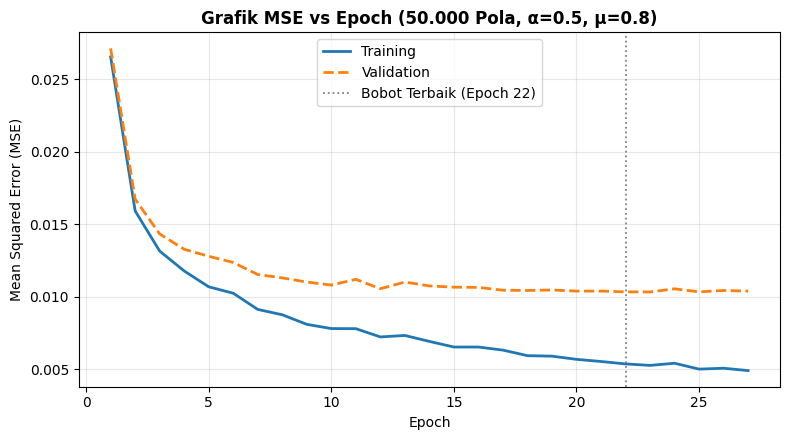

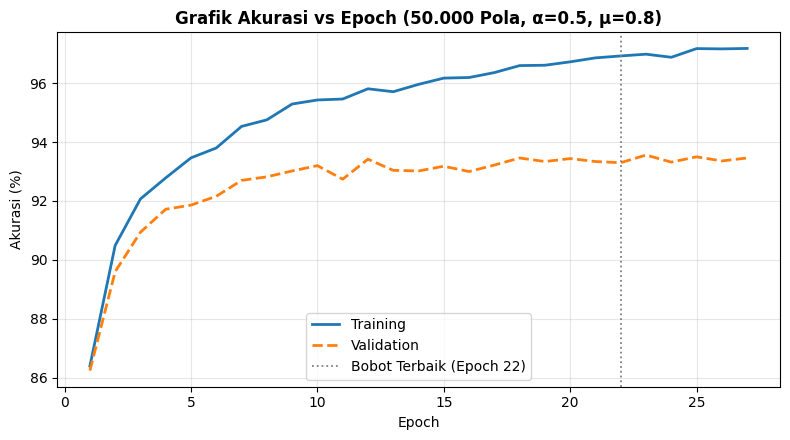

=== CLASSIFICATION REPORT (5.000 DATA UJI) ===
              precision    recall  f1-score   support

           0     0.9263    0.9800    0.9524       500
           1     0.9584    0.9680    0.9632       500
           2     0.9626    0.9260    0.9439       500
           3     0.9118    0.9100    0.9109       500
           4     0.9183    0.9440    0.9310       500
           5     0.9346    0.9140    0.9242       500
           6     0.9579    0.9560    0.9570       500
           7     0.9244    0.9540    0.9390       500
           8     0.9267    0.9100    0.9183       500
           9     0.9266    0.8840    0.9048       500

    accuracy                         0.9346      5000
   macro avg     0.9348    0.9346    0.9345      5000
weighted avg     0.9348    0.9346    0.9345      5000



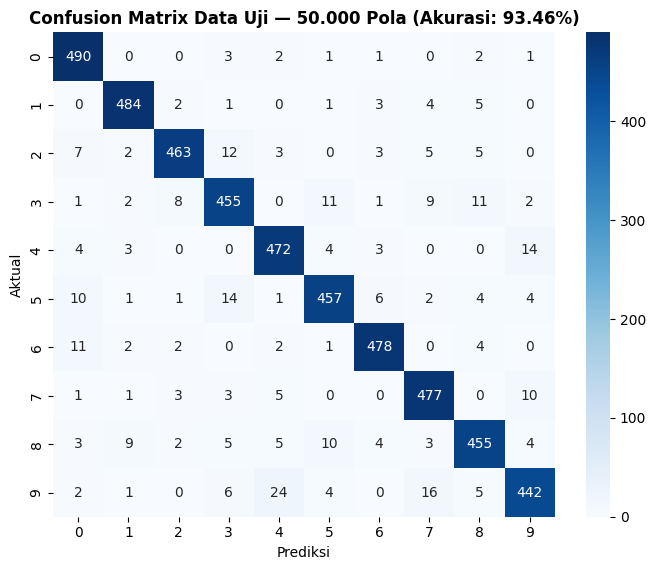

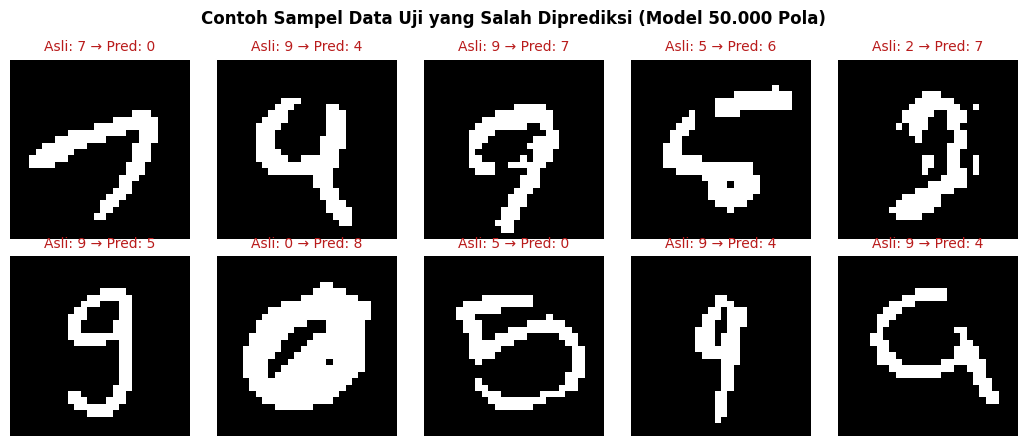

Melatih pembanding 400 data latih...
Melatih pembanding 1600 data latih...
Melatih pembanding 8000 data latih...

=== ANALISIS OVERFITTING MULTI-SKALA (5.000 DATA UJI SAMA) ===
 Setara Total Pola  Data Latih  Epoch Terbaik  Total Epoch  Akurasi Latih (%)  Akurasi Validasi (%)  Akurasi Uji (%)  Gap Latih-Uji (%)  MSE Uji                                Keterangan Berhenti
               500         400             99           99              99.25                 78.30            78.32              20.93   0.0327            Target MSE <= 0.005 tercapai (epoch 99)
              2000        1600             58           58              97.62                 85.66            86.16              11.47   0.0221            Target MSE <= 0.005 tercapai (epoch 58)
             10000        8000             30           30              97.35                 90.30            90.10               7.25   0.0155            Target MSE <= 0.005 tercapai (epoch 30)
             50000       40000         

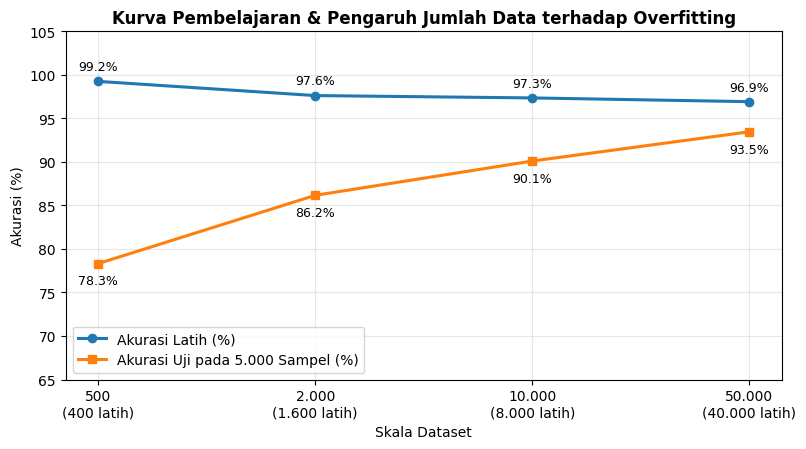

In [4]:
alpha_best, mu_best = param_terbaik

print("Melatih model utama 50.000 pola (40.000 data latih)...")
model_50k = BackpropNguyenWidrowMomentum(seed=42)
hist_50k = model_50k.fit(
    X_tr_50k, y_tr_50k, X_va_50k, y_va_50k,
    alpha=alpha_best, mu=mu_best,
    max_epoch=120, target_mse=0.005, batch_size=64,
    early_stopping=True, patience=20
)

# Sanity check model utama
assert model_50k.V1.shape == (784, 16) and model_50k.W3.shape == (16, 10)
assert 1 <= hist_50k['best_epoch'] <= hist_50k['epoch'][-1]
assert not np.isnan(model_50k.V1).any()

tr_mse_50k, tr_acc_50k = model_50k.evaluate(X_tr_50k, y_tr_50k)
va_mse_50k, va_acc_50k = model_50k.evaluate(X_va_50k, y_va_50k)
te_mse_50k, te_acc_50k = model_50k.evaluate(X_te_50k, y_te_50k)

print("\n=== HASIL MODEL UTAMA (50.000 POLA) ===")
print(f"Parameter       : α = {alpha_best}, μ = {mu_best}, batch_size = 64")
print(f"Status Berhenti : {hist_50k['stopped_reason']} (total {hist_50k['epoch'][-1]} epoch)")
print(f"Akurasi Latih   : {tr_acc_50k:.2f}% | MSE Latih    : {tr_mse_50k:.4f}")
print(f"Akurasi Validasi: {va_acc_50k:.2f}% | MSE Validasi : {va_mse_50k:.4f}")
print(f"Akurasi Uji     : {te_acc_50k:.2f}% | MSE Uji      : {te_mse_50k:.4f}")
print(f"Gap Latih-Uji   : {tr_acc_50k - te_acc_50k:.2f}%\n")

# Grafik Wajib 1 & 2: MSE vs Epoch & Akurasi vs Epoch
for y_tr_k, y_va_k, ylabel, title, fname in [
    ('train_mse', 'val_mse', 'Mean Squared Error (MSE)', f"Grafik MSE vs Epoch (50.000 Pola, α={alpha_best}, μ={mu_best})", "gambar_2_mse_vs_epoch_50k.png"),
    ('train_acc', 'val_acc', 'Akurasi (%)', f"Grafik Akurasi vs Epoch (50.000 Pola, α={alpha_best}, μ={mu_best})", "gambar_3_akurasi_vs_epoch_50k.png"),
]:
    plt.figure(figsize=(8, 4.5))
    plt.plot(hist_50k['epoch'], hist_50k[y_tr_k], label='Training', linewidth=2)
    plt.plot(hist_50k['epoch'], hist_50k[y_va_k], label='Validation', linewidth=2, linestyle='--')
    plt.axvline(hist_50k['best_epoch'], color='gray', linestyle=':', linewidth=1.3, label=f"Bobot Terbaik (Epoch {hist_50k['best_epoch']})")
    plt.title(title, fontweight='bold')
    plt.xlabel("Epoch"); plt.ylabel(ylabel)
    plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
    plt.savefig(fname, dpi=300); plt.show()

# Classification Report & Confusion Matrix (5.000 Data Uji)
y_pred_50k = model_50k.predict(X_te_50k)
print("=== CLASSIFICATION REPORT (5.000 DATA UJI) ===")
print(classification_report(y_te_50k, y_pred_50k, digits=4))

plt.figure(figsize=(7, 5.8))
sns.heatmap(confusion_matrix(y_te_50k, y_pred_50k), annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.title(f"Confusion Matrix Data Uji — 50.000 Pola (Akurasi: {te_acc_50k:.2f}%)", fontweight='bold')
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.tight_layout()
plt.savefig("gambar_4_cm_50k.png", dpi=300); plt.show()

# Bukti Visual 10 Sampel Uji Salah Prediksi
wrong_idx = np.where(y_pred_50k != y_te_50k)[0]
fig, axes = plt.subplots(2, 5, figsize=(10.5, 4.5))
for k, ax in enumerate(axes.flat):
    if k < len(wrong_idx):
        idx = wrong_idx[k]
        ax.imshow(X_te_50k[idx].reshape(28, 28), cmap='gray')
        ax.set_title(f"Asli: {y_te_50k[idx]} → Pred: {y_pred_50k[idx]}", fontsize=10, color='#b91c1c')
    ax.axis('off')
plt.suptitle("Contoh Sampel Data Uji yang Salah Diprediksi (Model 50.000 Pola)", fontsize=12, fontweight='bold')
plt.tight_layout(); plt.savefig("gambar_5_salah_prediksi_50k.png", dpi=300, bbox_inches='tight'); plt.show()

# Analisis Overfitting 4 Skala pada 5.000 Data Uji yang SAMA
hasil_overfit = []
for n_tr in [400, 1600, 8000, 40000]:
    if n_tr == 40000:
        tr_acc_s, va_acc_s, te_acc_s, te_mse_s = tr_acc_50k, va_acc_50k, te_acc_50k, te_mse_50k
        ep_best, ep_tot, alasan_s = hist_50k['best_epoch'], hist_50k['epoch'][-1], hist_50k['stopped_reason']
    else:
        print(f"Melatih pembanding {n_tr} data latih...")
        X_sub, _, y_sub, _ = train_test_split(X_tr_50k, y_tr_50k, train_size=n_tr, stratify=y_tr_50k, random_state=42)
        m_sub = BackpropNguyenWidrowMomentum(seed=42)
        h_sub = m_sub.fit(X_sub, y_sub, X_va_50k, y_va_50k, alpha=alpha_best, mu=mu_best,
                          max_epoch=150, target_mse=0.005, batch_size=64, early_stopping=False)
        _, tr_acc_s = m_sub.evaluate(X_sub, y_sub)
        _, va_acc_s = m_sub.evaluate(X_va_50k, y_va_50k)
        te_mse_s, te_acc_s = m_sub.evaluate(X_te_50k, y_te_50k)
        ep_best, ep_tot, alasan_s = h_sub['best_epoch'], h_sub['epoch'][-1], h_sub['stopped_reason']

    hasil_overfit.append({
        'Setara Total Pola': int(n_tr / 0.8), 'Data Latih': n_tr,
        'Epoch Terbaik': ep_best, 'Total Epoch': ep_tot,
        'Akurasi Latih (%)': round(tr_acc_s, 2), 'Akurasi Validasi (%)': round(va_acc_s, 2),
        'Akurasi Uji (%)': round(te_acc_s, 2), 'Gap Latih-Uji (%)': round(tr_acc_s - te_acc_s, 2),
        'MSE Uji': round(te_mse_s, 4), 'Keterangan Berhenti': alasan_s
    })

df_overfit = pd.DataFrame(hasil_overfit)
print("\n=== ANALISIS OVERFITTING MULTI-SKALA (5.000 DATA UJI SAMA) ===")
print(df_overfit.to_string(index=False))

plt.figure(figsize=(8.2, 4.6))
x_lbl = [f"{r['Setara Total Pola']:,}\n({r['Data Latih']:,} latih)".replace(",", ".") for r in hasil_overfit]
x_pos = np.arange(len(x_lbl))
plt.plot(x_pos, df_overfit['Akurasi Latih (%)'], marker='o', linewidth=2.2, label='Akurasi Latih (%)')
plt.plot(x_pos, df_overfit['Akurasi Uji (%)'], marker='s', linewidth=2.2, label='Akurasi Uji pada 5.000 Sampel (%)')
for i, (tr_v, te_v) in enumerate(zip(df_overfit['Akurasi Latih (%)'], df_overfit['Akurasi Uji (%)'])):
    plt.annotate(f"{tr_v:.1f}%", (x_pos[i], tr_v), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9)
    plt.annotate(f"{te_v:.1f}%", (x_pos[i], te_v), textcoords="offset points", xytext=(0, -15), ha='center', fontsize=9)
plt.xticks(x_pos, x_lbl)
plt.ylim(min(65, df_overfit['Akurasi Uji (%)'].min() - 5), 105)
plt.title("Kurva Pembelajaran & Pengaruh Jumlah Data terhadap Overfitting", fontweight='bold')
plt.xlabel("Skala Dataset"); plt.ylabel("Akurasi (%)")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig("gambar_6_learning_curve_overfitting.png", dpi=300); plt.show()

In [5]:
import numpy as np
from PIL import Image, ImageFilter
from google.colab import output
from IPython.display import display, HTML, JSON

def praproses_kanvas_ke_mnist_biner(pixels_56):
    img = np.array(pixels_56, dtype=np.float32).reshape(56, 56)
    if img.max() < 20:
        return np.zeros((28, 28), dtype=np.float32), True

    ys, xs = np.where(img > 25)
    crop = img[ys.min():ys.max()+1, xs.min():xs.max()+1]
    h, w = crop.shape
    scale = 20.0 / max(h, w)
    new_h, new_w = max(1, int(round(h * scale))), max(1, int(round(w * scale)))
    resample = getattr(Image, 'Resampling', Image).BILINEAR
    resized = np.array(Image.fromarray(crop.astype(np.uint8)).resize((new_w, new_h), resample), dtype=np.float32)

    canvas = np.zeros((28, 28), dtype=np.float32)
    top, left = (28 - new_h) // 2, (28 - new_w) // 2
    canvas[top:top+new_h, left:left+new_w] = resized

    canvas = np.array(Image.fromarray(canvas.astype(np.uint8)).filter(ImageFilter.GaussianBlur(radius=0.6)), dtype=np.float32)
    if canvas.max() > 0:
        canvas *= (255.0 / canvas.max())

    total = canvas.sum()
    if total > 0:
        gy, gx = np.indices((28, 28))
        sy, sx = int(round(13.5 - (gy * canvas).sum() / total)), int(round(13.5 - (gx * canvas).sum() / total))
        shifted = np.zeros_like(canvas)
        shifted[max(0, sy):min(28, 28+sy), max(0, sx):min(28, 28+sx)] = \
            canvas[max(0, -sy):min(28, 28-sy), max(0, -sx):min(28, 28-sx)]
        canvas = shifted

    return (canvas >= 128).astype(np.float32), False

def prediksi_dan_aktivasi(pixels_56):
    mdl = globals().get('model_50k') or globals().get('model_2k')
    if mdl is None:
        return JSON({"error": "Model belum dilatih. Jalankan Sel 1–4 dulu."})

    bin28, kosong = praproses_kanvas_ke_mnist_biner(pixels_56)
    if kosong:
        return JSON({"empty": True, "pred": -1, "bin28": [0]*784, "z1": [0.0]*16, "z2": [0.0]*16,
                     "y": [0.0]*10, "v2": mdl.V2.tolist(), "w3": mdl.W3.tolist()})

    Z1, Z2, Y = mdl.forward(bin28.reshape(1, 784))
    return JSON({
        "empty": False, "pred": int(np.argmax(Y[0])),
        "bin28": bin28.astype(int).flatten().tolist(),
        "z1": [round(float(v), 4) for v in Z1[0]],
        "z2": [round(float(v), 4) for v in Z2[0]],
        "y":  [round(float(v), 4) for v in Y[0]],
        "v2": np.round(mdl.V2, 3).tolist(),
        "w3": np.round(mdl.W3, 3).tolist(),
    })

output.register_callback('prediksi_jst', prediksi_dan_aktivasi)

html_ui = r"""
<style>
  .jst-app { font-family: 'Segoe UI', system-ui, sans-serif; background: #0d1117; color: #e6edf3; padding: 18px; border-radius: 14px; border: 1px solid #30363d; max-width: 1040px; box-sizing: border-box; --flow-dur: 0.45s; }
  .jst-header { display: flex; justify-content: space-between; align-items: center; margin-bottom: 12px; flex-wrap: wrap; gap: 10px; }
  .jst-title { font-size: 17px; font-weight: 700; color: #58a6ff; }
  .jst-sub { font-size: 12px; color: #8b949e; }
  .speed-wrap { display: flex; align-items: center; gap: 6px; font-size: 12px; color: #c9d1d9; }
  .speed-sel { background: #161b22; color: #e6edf3; border: 1px solid #30363d; border-radius: 6px; padding: 5px 8px; font-size: 12px; cursor: pointer; }
  .jst-grid { display: flex; gap: 18px; flex-wrap: wrap; align-items: flex-start; }
  .jst-left { width: 290px; display: flex; flex-direction: column; gap: 12px; }
  .jst-right { flex: 1; min-width: 470px; background: #161b22; border: 1px solid #30363d; border-radius: 10px; padding: 12px; }
  #drawCanvas { background: #000; border: 2px solid #388bfd; border-radius: 10px; cursor: crosshair; touch-action: none; display: block; }
  .jst-btns { display: flex; gap: 8px; }
  .jst-btn { flex: 1; padding: 10px 12px; border: none; border-radius: 8px; font-weight: 600; cursor: pointer; font-size: 13px; }
  .jst-btn:hover { opacity: 0.9; }
  .btn-clear { background: #30363d; color: #e6edf3; }
  .btn-pred  { background: #238636; color: #fff; }
  .jst-mini-row { display: flex; gap: 12px; align-items: center; background: #161b22; border: 1px solid #30363d; border-radius: 10px; padding: 10px; }
  #binCanvas { background: #000; border: 1px solid #484f58; border-radius: 4px; image-rendering: pixelated; }
  .pred-box { flex: 1; text-align: center; }
  .pred-label { font-size: 11px; color: #8b949e; text-transform: uppercase; letter-spacing: 0.5px; }
  .pred-digit { font-size: 46px; font-weight: 800; color: #f0b429; line-height: 1.05; transition: transform 0.25s; }
  .pred-digit.pop { transform: scale(1.16); }
  .pred-conf { font-size: 11.5px; color: #7ee787; margin-top: 3px; min-height: 16px; }
  .bars { background: #161b22; border: 1px solid #30363d; border-radius: 10px; padding: 10px 12px; }
  .bar-row { display: flex; align-items: center; gap: 8px; margin: 3px 0; font-size: 12px; }
  .bar-lbl { width: 14px; font-weight: 700; color: #c9d1d9; }
  .bar-track { flex: 1; height: 10px; background: #21262d; border-radius: 5px; overflow: hidden; }
  .bar-fill { height: 100%; width: 0%; background: #388bfd; border-radius: 5px; transition: width 0.4s ease-out; }
  .bar-fill.win { background: #f0b429; }
  .bar-val { width: 42px; text-align: right; color: #8b949e; font-variant-numeric: tabular-nums; }
  .steps-bar { display: flex; gap: 6px; margin-bottom: 8px; }
  .step-pill { flex: 1; text-align: center; font-size: 11px; font-weight: 600; padding: 6px 4px; border-radius: 6px; background: #0d1117; color: #6e7681; border: 1px solid #21262d; transition: all 0.25s; }
  .step-pill.done { color: #7ee787; border-color: #238636; background: #0f2417; }
  .step-pill.current { color: #fff; border-color: #58a6ff; background: #142a46; box-shadow: 0 0 8px rgba(88,166,255,0.35); }
  .step-pill.win { color: #0d1117; border-color: #f0b429; background: #f0b429; }
  .stage-msg { font-size: 12px; color: #c9d1d9; background: #0d1117; border: 1px solid #21262d; border-radius: 6px; padding: 6px 10px; margin-bottom: 6px; text-align: center; }
  .node-group { opacity: 0; transition: opacity 0.35s ease-out; }
  .node-group.show { opacity: 1; }
  .flow-group { opacity: 0; transition: opacity 0.12s linear; }
  .flow-group.active { opacity: 1; }
  .flow-group.active line { stroke-dashoffset: 0 !important; transition: stroke-dashoffset var(--flow-dur) ease-out; }
  .win-ring { opacity: 0; transition: opacity 0.35s ease-out; }
  .win-ring.show { opacity: 1; }
  .legend { display: flex; gap: 14px; font-size: 11px; color: #8b949e; margin-top: 6px; justify-content: center; flex-wrap: wrap; }
  .dot { display: inline-block; width: 9px; height: 9px; border-radius: 50%; margin-right: 4px; vertical-align: middle; }
</style>

<div class="jst-app" id="jstApp">
  <div class="jst-header">
    <div>
      <div class="jst-title">Visualizer Bertahap JST 784–16–16–10</div>
      <div class="jst-sub">Gambar angka 0–9 sampai selesai, lalu klik <b>Tebak Angka</b>.</div>
    </div>
    <div class="speed-wrap">
      <label for="speedSel">Kecepatan:</label>
      <select id="speedSel" class="speed-sel">
        <option value="normal" selected>Normal</option>
        <option value="lambat">Lambat (Detail)</option>
      </select>
    </div>
  </div>
  <div class="jst-grid">
    <div class="jst-left">
      <canvas id="drawCanvas" width="280" height="280"></canvas>
      <div class="jst-btns">
        <button class="jst-btn btn-clear" onclick="clearCanvas()">Hapus</button>
        <button class="jst-btn btn-pred" onclick="runPredict()">Tebak Angka ▶</button>
      </div>
      <div class="jst-mini-row">
        <div style="text-align:center;">
          <canvas id="binCanvas" width="84" height="84"></canvas>
          <div style="font-size:10px;color:#8b949e;margin-top:3px;">Input Biner 28×28</div>
        </div>
        <div class="pred-box">
          <div class="pred-label">Prediksi Jaringan</div>
          <div id="predDigit" class="pred-digit">-</div>
          <div id="predConf" class="pred-conf">Gambar angka, lalu klik Tebak</div>
        </div>
      </div>
      <div class="bars" id="barsBox"></div>
    </div>
    <div class="jst-right">
      <div class="steps-bar">
        <div id="st1" class="step-pill">1. Input (784)</div>
        <div id="st2" class="step-pill">2. Hidden 1 (16)</div>
        <div id="st3" class="step-pill">3. Hidden 2 (16)</div>
        <div id="st4" class="step-pill">4. Output (0–9)</div>
      </div>
      <div id="stageMsg" class="stage-msg">Menunggu gambar angka...</div>
      <svg id="netSvg" viewBox="0 0 640 495" width="100%" height="475"></svg>
      <div class="legend">
        <span><span class="dot" style="background:#fff;border:1px solid #58a6ff;"></span>Neuron Aktif</span>
        <span><span class="dot" style="background:#38bdf8;"></span>Sinapsis (+)</span>
        <span><span class="dot" style="background:#f87171;"></span>Sinapsis (−)</span>
        <span><span class="dot" style="background:#f0b429;"></span>Pemenang</span>
      </div>
    </div>
  </div>
</div>

<script>
const appEl = document.getElementById('jstApp'), canvas = document.getElementById('drawCanvas'), ctx = canvas.getContext('2d');
const binCtx = document.getElementById('binCanvas').getContext('2d'), svg = document.getElementById('netSvg');
const barsBox = document.getElementById('barsBox'), stageMsg = document.getElementById('stageMsg');
const predDigitEl = document.getElementById('predDigit'), predConfEl = document.getElementById('predConf');
let animTimers = [], drawing = false;
const stopAnimations = () => { animTimers.forEach(clearTimeout); animTimers = []; };

for (let d = 0; d < 10; d++) {
  barsBox.innerHTML += `<div class="bar-row"><div class="bar-lbl">${d}</div><div class="bar-track"><div id="bar_${d}" class="bar-fill"></div></div><div id="val_${d}" class="bar-val">0.0%</div></div>`;
}
ctx.fillStyle = '#000'; ctx.fillRect(0, 0, 280, 280);
ctx.strokeStyle = '#fff'; ctx.lineWidth = 28; ctx.lineCap = 'round'; ctx.lineJoin = 'round';

function getPos(e) {
  const r = canvas.getBoundingClientRect(), pt = e.touches ? e.touches[0] : e;
  return { x: (pt.clientX - r.left) * (280 / r.width), y: (pt.clientY - r.top) * (280 / r.height) };
}
const startDraw = e => { e.preventDefault(); drawing = true; const p = getPos(e); ctx.beginPath(); ctx.moveTo(p.x, p.y); predConfEl.textContent = "Klik 'Tebak Angka' jika selesai"; };
const moveDraw  = e => { if (!drawing) return; e.preventDefault(); const p = getPos(e); ctx.lineTo(p.x, p.y); ctx.stroke(); ctx.beginPath(); ctx.moveTo(p.x, p.y); };
const endDraw   = () => { drawing = false; };
canvas.addEventListener('mousedown', startDraw); canvas.addEventListener('mousemove', moveDraw); window.addEventListener('mouseup', endDraw);
canvas.addEventListener('touchstart', startDraw, {passive: false}); canvas.addEventListener('touchmove', moveDraw, {passive: false}); window.addEventListener('touchend', endDraw);

function setStepState(activeStep, isFinalWin=false) {
  for (let s = 1; s <= 4; s++) {
    const el = document.getElementById('st' + s);
    el.className = 'step-pill' + (activeStep === 0 ? '' : s < activeStep ? ' done' : s === activeStep ? (isFinalWin ? ' win' : ' current') : '');
  }
}
function resetBars() {
  for (let d = 0; d < 10; d++) {
    document.getElementById('bar_' + d).style.width = '0%';
    document.getElementById('bar_' + d).className = 'bar-fill';
    document.getElementById('val_' + d).textContent = '0.0%';
  }
}
function clearCanvas() {
  stopAnimations();
  ctx.fillStyle = '#000'; ctx.fillRect(0, 0, 280, 280);
  binCtx.fillStyle = '#000'; binCtx.fillRect(0, 0, 84, 84);
  predDigitEl.textContent = '-'; predDigitEl.classList.remove('pop');
  predConfEl.textContent = 'Kanvas dibersihkan'; stageMsg.textContent = 'Menunggu gambar angka...';
  setStepState(0); resetBars(); buildNetworkSVG(null);
}

async function runPredict() {
  stopAnimations();
  const tmp = document.createElement('canvas'); tmp.width = 56; tmp.height = 56;
  const tctx = tmp.getContext('2d'); tctx.drawImage(canvas, 0, 0, 56, 56);
  const data = tctx.getImageData(0, 0, 56, 56).data, gray56 = [];
  for (let i = 0; i < data.length; i += 4) gray56.push(data[i]);

  try {
    stageMsg.textContent = 'Memproses citra...';
    const res = await google.colab.kernel.invokeFunction('prediksi_jst', [gray56], {});
    const out = res.data['application/json'];
    if (out.error) { predConfEl.textContent = out.error; stageMsg.textContent = out.error; return; }
    if (out.empty) { predConfEl.textContent = 'Kanvas masih kosong!'; stageMsg.textContent = 'Gambar angka 0–9 terlebih dahulu.'; setStepState(0); return; }

    const slow = document.getElementById('speedSel').value === 'lambat';
    const stageGap = slow ? 1250 : 720, flowDur = slow ? 0.80 : 0.45;
    appEl.style.setProperty('--flow-dur', flowDur + 's');

    resetBars(); predDigitEl.textContent = '?'; predDigitEl.classList.remove('pop');
    predConfEl.textContent = 'Propagasi maju...';
    binCtx.fillStyle = '#000'; binCtx.fillRect(0, 0, 84, 84);
    buildNetworkSVG(out); void svg.getBoundingClientRect();

    animTimers.push(setTimeout(() => {
      setStepState(1); stageMsg.textContent = 'Tahap 1/4: Praproses biner 28×28 (T=128) → 784 neuron Input aktif';
      binCtx.fillStyle = '#fff';
      for (let r = 0; r < 28; r++) for (let c = 0; c < 28; c++) if (out.bin28[r*28+c] === 1) binCtx.fillRect(c*3, r*3, 3, 3);
      document.getElementById('g-nodes-in').classList.add('show');
    }, 50));

    animTimers.push(setTimeout(() => { setStepState(2); stageMsg.textContent = 'Tahap 2/4: Sinyal mengalir lewat V⁽¹⁾ → Hidden Layer 1 (16 neuron)'; document.getElementById('g-edges-1').classList.add('active'); }, stageGap));
    animTimers.push(setTimeout(() => { document.getElementById('g-nodes-h1').classList.add('show'); }, stageGap + Math.round(flowDur * 750)));

    animTimers.push(setTimeout(() => { setStepState(3); stageMsg.textContent = 'Tahap 3/4: Sinyal mengalir lewat V⁽²⁾ → Hidden Layer 2 (16 neuron)'; document.getElementById('g-edges-2').classList.add('active'); }, stageGap * 2));
    animTimers.push(setTimeout(() => { document.getElementById('g-nodes-h2').classList.add('show'); }, stageGap * 2 + Math.round(flowDur * 750)));

    animTimers.push(setTimeout(() => { setStepState(4, false); stageMsg.textContent = 'Tahap 4/4: Sinyal mengalir lewat W⁽³⁾ → 10 kelas Output...'; document.getElementById('g-edges-3').classList.add('active'); }, stageGap * 3));
    animTimers.push(setTimeout(() => {
      document.getElementById('g-nodes-out').classList.add('show');
      document.getElementById('g-win-ring').classList.add('show');
      setStepState(4, true);
      predDigitEl.textContent = out.pred; predDigitEl.classList.add('pop');
      const sumY = out.y.reduce((a, b) => a + b, 0) + 1e-9;
      predConfEl.textContent = `Aktivasi Y = ${out.y[out.pred].toFixed(3)} (${((out.y[out.pred]/sumY)*100).toFixed(1)}% relatif)`;
      stageMsg.innerHTML = `Selesai! Prediksi: <b style="color:#f0b429;">Angka ${out.pred}</b> (Y = ${out.y[out.pred].toFixed(3)}).`;
      for (let d = 0; d < 10; d++) {
        const pct = Math.min(100, out.y[d] * 100), bar = document.getElementById('bar_' + d);
        bar.style.width = pct.toFixed(1) + '%'; bar.className = 'bar-fill' + (d === out.pred ? ' win' : '');
        document.getElementById('val_' + d).textContent = pct.toFixed(1) + '%';
      }
    }, stageGap * 3 + Math.round(flowDur * 850)));
  } catch (err) { predConfEl.textContent = 'Jalankan Sel 1–4 dulu!'; stageMsg.textContent = 'Error koneksi ke kernel Colab.'; console.error(err); }
}

function buildNetworkSVG(out) {
  const X_IN = 72, X_H1 = 236, X_H2 = 414, X_OUT = 562;
  const yPos = (n, a, b) => Array.from({length: n}, (_, i) => a + (i*(b-a))/Math.max(1, n-1));
  const yIn = yPos(16, 60, 468), yH1 = yPos(16, 60, 468), yH2 = yPos(16, 60, 468), yOut = yPos(10, 102, 426);
  let html = '';
  for (const [x, t1, t2] of [[X_IN,'Input Layer','784 Piksel (16 blok)'],[X_H1,'Hidden Layer 1','16 Neuron (Sigmoid)'],[X_H2,'Hidden Layer 2','16 Neuron (Sigmoid)'],[X_OUT,'Output Layer','10 Kelas (0–9)']])
    html += `<text x="${x}" y="22" text-anchor="middle" fill="#c9d1d9" font-size="12" font-weight="700">${t1}</text><text x="${x}" y="37" text-anchor="middle" fill="#8b949e" font-size="10">${t2}</text>`;

  html += `<g id="g-base">`;
  for (let i = 0; i < 16; i++) {
    for (let j = 0; j < 16; j++)
      html += `<line x1="${X_IN}" y1="${yIn[i]}" x2="${X_H1}" y2="${yH1[j]}" stroke="#30363d" stroke-opacity="0.16" stroke-width="0.5"/><line x1="${X_H1}" y1="${yH1[i]}" x2="${X_H2}" y2="${yH2[j]}" stroke="#30363d" stroke-opacity="0.16" stroke-width="0.5"/>`;
    for (let j = 0; j < 10; j++)
      html += `<line x1="${X_H2}" y1="${yH2[i]}" x2="${X_OUT}" y2="${yOut[j]}" stroke="#30363d" stroke-opacity="0.16" stroke-width="0.5"/>`;
  }
  const baseNodes = (x, ys, isOut=false) => ys.map((y, i) => `<circle cx="${x}" cy="${y}" r="${isOut?13:9.2}" fill="#161b22" stroke="#30363d" stroke-width="1.2"/>` + (isOut ? `<text x="${x}" y="${y+4}" text-anchor="middle" fill="#6e7681" font-size="11" font-weight="700">${i}</text>` : '')).join('');
  html += baseNodes(X_IN, yIn) + baseNodes(X_H1, yH1) + baseNodes(X_H2, yH2) + baseNodes(X_OUT, yOut, true) + `</g>`;
  if (!out) { svg.innerHTML = html; return; }

  const inRep = Array.from({length: 16}, (_, i) => {
    let s = 0; for (let k = Math.floor(i*784/16); k < Math.floor((i+1)*784/16); k++) s += out.bin28[k];
    return Math.min(1, s / 10);
  });
  const lineAnim = (x1, y1, x2, y2, col, op, w) => {
    const L = Math.hypot(x2 - x1, y2 - y1).toFixed(1);
    return `<line x1="${x1}" y1="${y1}" x2="${x2}" y2="${y2}" stroke="${col}" stroke-opacity="${op}" stroke-width="${w}" style="stroke-dasharray:${L};stroke-dashoffset:${L};"/>`;
  };

  html += `<g id="g-edges-1" class="flow-group">`;
  for (let i = 0; i < 16; i++) for (let j = 0; j < 16; j++) { const st = inRep[i]*out.z1[j]; if (st > 0.08) html += lineAnim(X_IN, yIn[i], X_H1, yH1[j], '#38bdf8', (0.15+st*0.5).toFixed(2), (0.6+st*1.5).toFixed(2)); }
  html += `</g><g id="g-edges-2" class="flow-group">`;
  for (let i = 0; i < 16; i++) for (let j = 0; j < 16; j++) { const c = out.z1[i]*out.v2[i][j], mag = Math.min(1, Math.abs(c)/2.2); if (mag > 0.08) html += lineAnim(X_H1, yH1[i], X_H2, yH2[j], c>=0?'#38bdf8':'#f87171', (0.18+mag*0.72).toFixed(2), (0.6+mag*2.0).toFixed(2)); }
  html += `</g><g id="g-edges-3" class="flow-group">`;
  for (let i = 0; i < 16; i++) for (let j = 0; j < 10; j++) { const c = out.z2[i]*out.w3[i][j], mag = Math.min(1, Math.abs(c)/2.2); if (mag > 0.08) html += lineAnim(X_H2, yH2[i], X_OUT, yOut[j], (j===out.pred&&c>0)?'#f0b429':(c>=0?'#38bdf8':'#f87171'), (0.20+mag*0.78).toFixed(2), (0.7+mag*2.4).toFixed(2)); }
  html += `</g>`;

  const activeNodes = (id, x, ys, vals, isOut=false) => `<g id="${id}" class="node-group">` + ys.map((y, i) => {
    const v = vals[i], b = Math.round(22 + v*233), win = isOut && i === out.pred;
    return `<circle cx="${x}" cy="${y}" r="${isOut?13:9.2}" fill="${win?'#f0b429':`rgb(${b},${b},${Math.min(255,b+18)})`}" stroke="${win?'#fff':'#58a6ff'}" stroke-width="${win?2.5:1.3}"/>` +
      (isOut ? `<text x="${x}" y="${y+4}" text-anchor="middle" fill="${v>0.55||win?'#0d1117':'#e6edf3'}" font-size="11" font-weight="800">${i}</text><text x="${x+20}" y="${y+4}" fill="${win?'#f0b429':'#8b949e'}" font-size="10.5" font-weight="${win?'700':'400'}">${v.toFixed(2)}</text>` : '');
  }).join('') + `</g>`;

  html += activeNodes('g-nodes-in', X_IN, yIn, inRep) + activeNodes('g-nodes-h1', X_H1, yH1, out.z1)
        + activeNodes('g-nodes-h2', X_H2, yH2, out.z2) + activeNodes('g-nodes-out', X_OUT, yOut, out.y, true)
        + `<g id="g-win-ring" class="win-ring"><circle cx="${X_OUT}" cy="${yOut[out.pred]}" r="18" fill="none" stroke="#f0b429" stroke-width="2" stroke-opacity="0.8"/></g>`;
  svg.innerHTML = html;
}
buildNetworkSVG(null);
</script>
"""
display(HTML(html_ui))